# 第1章　ベイズ最適化とは何か

処理温度を $140$ ～ $180\,^\circ\mathrm{C}$ の間で変え、合成試験の強度を最大化します。温度は $x=(T-140)/40$ に写し、候補は $\{0,0.025,\ldots,1\}$ とします。最初の3点から次の1点を提案した後、同じ合成試験を三つの方法・同じ評価予算で比べます。

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import torch
from botorch.acquisition.analytic import LogExpectedImprovement
from botorch.optim import optimize_acqf_discrete

from experiment import (
    BLUE, DTYPE, GREEN, ORANGE, QUALITY, SEED,
    fit_material_gp, material_strength, save_figure, setup,
)

setup()
pool = torch.linspace(0, 1, 41, dtype=DTYPE).unsqueeze(-1)
initial_ids = torch.tensor([4, 20, 36])
train_x = pool[initial_ids]
train_y = material_strength(train_x)
available = torch.ones(len(pool), dtype=torch.bool)
available[initial_ids] = False

# シミュレータは決定論的。モデルの計算では小さな観測分散を指定する。
train_yvar = torch.full_like(train_y, 0.01)
model = fit_material_gp(train_x, train_y, train_yvar)
acquisition = LogExpectedImprovement(model, best_f=train_y.max())
candidate, _ = optimize_acqf_discrete(acquisition, q=1, choices=pool[available])
candidate_y = material_strength(candidate)
print("最初の3点 [°C]:", (140 + 40 * train_x[:, 0]).tolist())
print(f"次の温度: {140 + 40 * candidate.item():.0f} °C")
print(f"その温度を評価した強度: {candidate_y.item():.2f} MPa")

最初の3点 [°C]: [144.0, 160.0, 176.0]
次の温度: 150 °C
その温度を評価した強度: 79.25 MPa


## 1.2 初期観測・GPの予測・次の候補
上段の帯は、3点を学習したGPの潜在強度の点ごとの区間です。下段の丸印は探索で得た候補です。上下段で同じ温度を読み、事後平均の高い場所とLogEIの最大がどのように対応するかを見ます。ログの値を強度に換算する必要はありません。

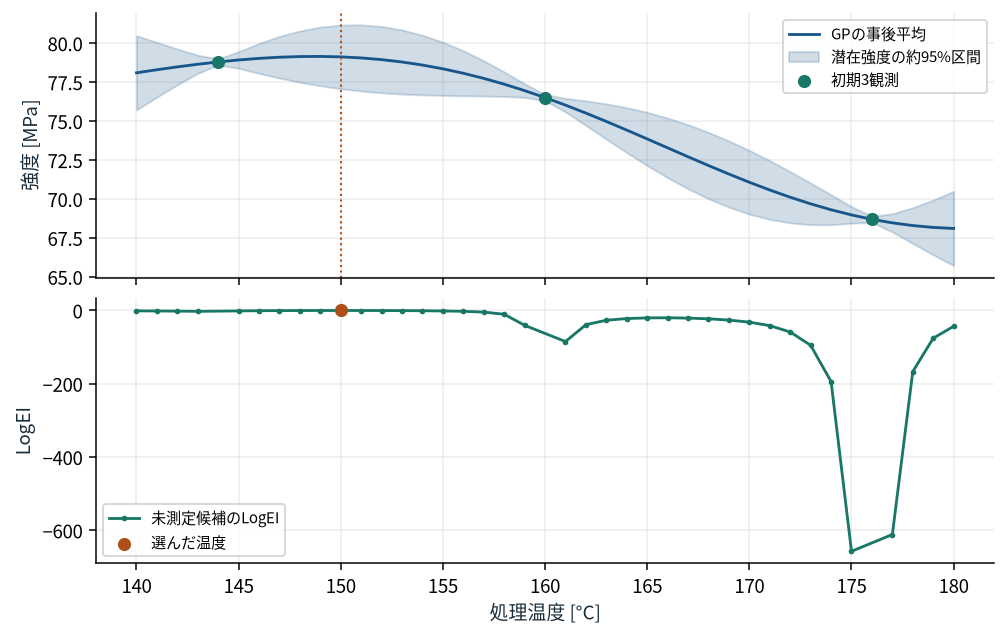

In [2]:
with torch.no_grad():
    posterior = model.posterior(pool)
    mean = posterior.mean[:, 0]
    sd = posterior.variance[:, 0].sqrt()
    scores = acquisition(pool.unsqueeze(-2))

temperature = 140 + 40 * pool[:, 0]
next_temp = 140 + 40 * candidate.item()
next_id = int(torch.argmin((pool[:, 0] - candidate.item()).abs()))
fig, (ax, bx) = plt.subplots(2, 1, figsize=(7.35, 4.6), sharex=True, layout="constrained")
ax.plot(temperature, mean, color=BLUE, label="GPの事後平均")
ax.fill_between(temperature, mean - 1.96 * sd, mean + 1.96 * sd,
                color=BLUE, alpha=0.20, label="潜在強度の約95%区間")
ax.scatter(140 + 40 * train_x[:, 0], train_y[:, 0], color=GREEN,
           zorder=4, label="初期3観測")
ax.axvline(next_temp, color=ORANGE, linewidth=1.1, linestyle=":")
ax.set_ylabel("強度 [MPa]")
ax.legend(loc="best", fontsize=8)
bx.plot(temperature[available], scores[available], "o-", color=GREEN, markersize=2,
        label="未測定候補のLogEI")
bx.scatter(next_temp, scores[next_id], color=ORANGE, zorder=4, label="選んだ温度")
bx.set(xlabel="処理温度 [°C]", ylabel="LogEI")
bx.legend(loc="best", fontsize=8)
save_figure(fig, "ch01_first_proposal")

## 1.5 同じ予算で三つの選び方を比べる
追加の6点には、ランダムで選ぶ方法、固定間隔の格子に従う方法、観測を毎回更新するBOを用います。既に測定した点は除外します。横軸は初期3点を含む評価回数です。合成真値全体は比較と図の参照のため、探索終了後に計算します。

{
  "ランダム": {
    "best_mpa": 79.92402700604445,
    "best_temperature_c": 157.0,
    "evaluation_count": 9,
    "temperature_sequence_c": [
      144.0,
      160.0,
      176.0,
      165.0,
      142.0,
      157.0,
      171.0,
      167.0,
      177.0
    ]
  },
  "固定格子": {
    "best_mpa": 80.28949100500947,
    "best_temperature_c": 156.0,
    "evaluation_count": 9,
    "temperature_sequence_c": [
      144.0,
      160.0,
      176.0,
      140.0,
      148.0,
      156.0,
      164.0,
      172.0,
      180.0
    ]
  },
  "ベイズ最適化": {
    "best_mpa": 80.22213595499959,
    "best_temperature_c": 154.0,
    "evaluation_count": 9,
    "temperature_sequence_c": [
      144.0,
      160.0,
      176.0,
      150.0,
      149.0,
      148.0,
      151.0,
      140.0,
      154.0
    ]
  }
}


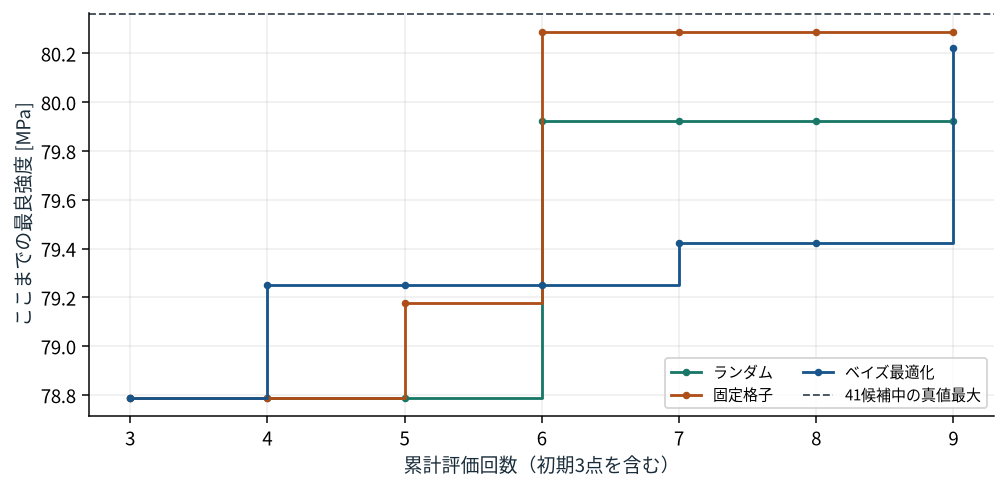

In [3]:
n_extra = 6
random_generator = torch.Generator().manual_seed(SEED)
open_ids = torch.where(available)[0]
random_ids = open_ids[torch.randperm(len(open_ids), generator=random_generator)[:n_extra]]
grid_ids = torch.arange(0, 41, 8)[:n_extra]

bo_ids = torch.cat((initial_ids, torch.tensor([next_id])))
bo_y = torch.cat((train_y, candidate_y))
for _ in range(1, n_extra):
    open_mask = torch.ones(len(pool), dtype=torch.bool)
    open_mask[bo_ids] = False
    gp = fit_material_gp(pool[bo_ids], bo_y, torch.full_like(bo_y, 0.01))
    value = LogExpectedImprovement(gp, best_f=bo_y.max())
    point, _ = optimize_acqf_discrete(value, q=1, choices=pool[open_mask])
    point_id = torch.argmin((pool[:, 0] - point.item()).abs()).reshape(1)
    bo_ids = torch.cat((bo_ids, point_id))
    bo_y = torch.cat((bo_y, material_strength(point)))

choices = {
    "ランダム": torch.cat((initial_ids, random_ids)),
    "固定格子": torch.cat((initial_ids, grid_ids)),
    "ベイズ最適化": bo_ids,
}
# 経過曲線には登録済み観測だけを使う。真値全体は探索後の参照線に使う。
observed = {
    "ランダム": torch.cat((train_y, material_strength(pool[random_ids]))),
    "固定格子": torch.cat((train_y, material_strength(pool[grid_ids]))),
    "ベイズ最適化": bo_y,
}
oracle = material_strength(pool).max().item()
fig, ax = plt.subplots(figsize=(7.35, 3.5), layout="constrained")
results = {}
for (label, ids), color in zip(choices.items(), (GREEN, ORANGE, BLUE)):
    y = observed[label][:, 0]
    assert len(ids) == len(ids.unique()) == len(initial_ids) + n_extra
    assert torch.equal(ids[:len(initial_ids)], initial_ids)
    best = y.cummax(0).values
    ax.step(range(3, len(ids)+1), best[2:], where="post", color=color,
            marker="o", markersize=3, label=label)
    argbest = y.argmax()
    results[label] = {
        "best_mpa": y[argbest].item(),
        "best_temperature_c": temperature[ids[argbest]].item(),
        "evaluation_count": len(ids),
        "temperature_sequence_c": temperature[ids].tolist(),
    }
ax.axhline(oracle, color="#45515b", linewidth=1, linestyle="--", label="41候補中の真値最大")
ax.set(xlabel="累計評価回数（初期3点を含む）", ylabel="ここまでの最良強度 [MPa]")
ax.set_xticks(list(range(3, len(initial_ids)+n_extra+1)))
ax.legend(loc="lower right", fontsize=8, ncols=2)
save_figure(fig, "ch01_budget_comparison")

metrics = {
    "first_temperature_c": next_temp, "first_observed_mpa": candidate_y.item(),
    "initial_count": len(initial_ids), "extra_count": n_extra,
    "best_possible_mpa": oracle, "results": results,
}
(QUALITY / "ch01_metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(json.dumps(results, ensure_ascii=False, indent=2))

## 章末演習
1. **確認。** 初期3点、追加6点の試験で評価予算はいくつですか。候補集合を41点から細かくすると、物理的な試験回数もそのまま増えるでしょうか。
2. **操作。** `n_extra` を3に変え、何回目までに各方法がどの強度に達したかを比べましょう。次にランダムのシードを変え、最良値が動くか確かめます。
3. **発展。** 同じ温度を繰り返し測ると強度がばらつく場合、図の最良観測値をどう読みますか。最良条件を推薦する前に追加で行う測定を説明しましょう。